In [1]:
%load_ext autoreload
%autoreload 2

# I. Modeling

Since our model is designed to encode the attributes of each entity (**type, size, color, and orientation angle**) we adopt a **multi-task CNN encoder architecture**. 

The encoder is jointly trained to predict these attributes from the visual input (crops) and to learn a compact **latent representation**. 

This latent vector will be combined with the entity’s **spatial and structural information** (**problem ID, panel ID, and bounding boxes**).

The resulting feature representation is then provided to the **graph construction module**, which uses these attributes to construct the graph representation that will ultimately be processed by the **GNN**.



## 1. Visual Encoder (CNN)

we choose to use a multi-task CNN architecture 
<div align="center">
  <img src="../assets/images/MT-CNN_GB.drawio.png" alt="Alt text">
</div>

**Getting the data**

In [1]:
# test the output shape of the model
# we need first to grab the data 

import torch
from hri_gnn.datasets import RavenDataset , gnn_flat_collate
from torch.utils.data import DataLoader

# Fixing the seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Train dataset
train_dataset = RavenDataset(
    dataset="raven-20000",
    split="train",
    percentage_limit=0.0025
)
# Test dataset
test_dataset = RavenDataset(
    dataset="raven-20000",
    split="test",
    percentage_limit=0.0025
)
# Validation dataset
val_dataset = RavenDataset(
    dataset="raven-20000",
    split="val",
    percentage_limit=0.0025
)
# Train DataLoader
train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=5,
    shuffle=True,
    collate_fn= gnn_flat_collate
)
# Test DataLoader
test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=5,
    shuffle=False,
    collate_fn= gnn_flat_collate
)
# Validation DataLoader
val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=5,
    shuffle=False,
    collate_fn= gnn_flat_collate
)


In [2]:
# Checking datasets lengths 
len(train_dataset) ,len(val_dataset), len(test_dataset)

(203, 67, 67)

In [3]:
# Instanciating the model

import torch
from hri_gnn.models.cnn_encoder import RavenCnnEncoder

# Fixing the seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# make the code device agnostic 
device = "cuda" if torch.cuda.is_available() else "cpu"
# printing the device
print(f"the available device is:{device}")

cnn_encoder = RavenCnnEncoder().to(device)

the available device is:cuda


**Training the model**

In [4]:
import torch 
from hri_gnn.training.trainer import Trainer
from hri_gnn.losses import CompositeLoss
from hri_gnn.metrics import TrainingTimer

criterion = CompositeLoss()
optimizer = torch.optim.Adam(params=cnn_encoder.parameters(),lr=1e-4)
with TrainingTimer(model= cnn_encoder) as train_timer:
    raven_trainer = Trainer(
                        model=cnn_encoder, 
                        optimizer=optimizer, 
                        criterion=criterion,
                        metrics_detials=True,
                        loss_details=True)
    taining_output = raven_trainer.fit(train_dataloader,test_dataloader,epochs=3, verbose=True)
model_training_time = train_timer.elapsed


start training model: RavenCnnEncoder...
No device provided, Trainer will use: cuda
No device was specified, CompositeMetric is setting device to: cuda


  0%|          | 0/3 [00:00<?, ?it/s]

Epoque 1/3: 
- Train (Test) losses: loss: 7.8616 (7.3230) - loss_type: 1.7196 (1.5768) - loss_size: 1.7341 (1.5351) - loss_color: 2.1851 (2.0962) - loss_angle: 2.2228 (2.1149) - 
- Train (Test) Metrics :accuracy: 0.2088 (0.2465) - precision: 0.1528 (0.2113) - recall: 0.2088 (0.2465) - f1: 0.1369 (0.1889) - accuracy_type: 0.2728 (0.2965) - accuracy_size: 0.2829 (0.3923) - accuracy_color: 0.1478 (0.1603) - accuracy_angle: 0.1318 (0.1368) - precision_type: 0.2064 (0.2320) - precision_size: 0.2280 (0.4689) - precision_color: 0.0789 (0.0763) - precision_angle: 0.0978 (0.0680) - recall_type: 0.2728 (0.2965) - recall_size: 0.2829 (0.3923) - recall_color: 0.1478 (0.1603) - recall_angle: 0.1318 (0.1368) - f1_type: 0.1928 (0.2230) - f1_size: 0.1947 (0.3710) - f1_color: 0.0825 (0.0817) - f1_angle: 0.0776 (0.0800) - 
Epoque 2/3: 
- Train (Test) losses: loss: 7.0783 (7.0320) - loss_type: 1.5441 (1.5408) - loss_size: 1.4584 (1.4115) - loss_color: 1.9623 (1.9657) - loss_angle: 2.1135 (2.1141) - 
- Tr

In [5]:
validation_result = raven_trainer.validate(val_dataloader=val_dataloader)
validation_result

Validating the model...:   0%|          | 0/14 [00:00<?, ?it/s]

{'val_loss': 6.410747630255563,
 'val_loss_type': 1.395915925502777,
 'val_loss_size': 1.183460967881339,
 'val_loss_color': 1.8260823913982935,
 'val_loss_angle': 2.005288336958204,
 'val_accuracy': 0.3464238574462278,
 'val_precision': 0.3576207706438644,
 'val_recall': 0.3464238574462278,
 'val_f1': 0.2908262408205441,
 'val_accuracy_type': 0.37805281579494476,
 'val_accuracy_size': 0.5470687044518334,
 'val_accuracy_color': 0.2578311434813908,
 'val_accuracy_angle': 0.202742766056742,
 'val_precision_type': 0.39122241948332104,
 'val_precision_size': 0.5632486577544894,
 'val_precision_color': 0.2400307527610234,
 'val_precision_angle': 0.23598125257662364,
 'val_recall_type': 0.37805281579494476,
 'val_recall_size': 0.5470687044518334,
 'val_recall_color': 0.2578311434813908,
 'val_recall_angle': 0.202742766056742,
 'val_f1_type': 0.3174564146569797,
 'val_f1_size': 0.5014473284993853,
 'val_f1_color': 0.18640073814562388,
 'val_f1_angle': 0.15800048198018754,
 'val_num_of_crops':

In [47]:
history = taining_output
history

{'train_loss': [7.86164409358327, 7.078251896834955, 6.622326583397098],
 'test_loss': [7.322970867156982, 7.032001495361328, 6.365540845053537],
 'train_loss_type': [1.719629581381635,
  1.5440933151942928,
  1.4765317556334705],
 'test_loss_type': [1.5768324647630965,
  1.5407620923859733,
  1.4126562476158142],
 'train_loss_size': [1.7341289142282998,
  1.4583587908163302,
  1.263037934535887],
 'test_loss_size': [1.5350720030920846,
  1.4114654915673392,
  1.1288391862596785],
 'train_loss_color': [2.1851114238180767,
  1.9623414801388253,
  1.8255207451378428],
 'test_loss_color': [2.0961803708757674,
  1.9657190782683236,
  1.816778404372079],
 'train_loss_angle': [2.2227741508949093,
  2.113458299055332,
  2.0572361480898973],
 'test_loss_angle': [2.1148859603064403,
  2.1140548161097934,
  2.007266938686371],
 'train_accuracy': [0.2088213274028243,
  0.2829152943975315,
  0.3272320054380632],
 'test_accuracy': [0.24647537126605, 0.26754478990499464, 0.35007238760590553],
 'trai

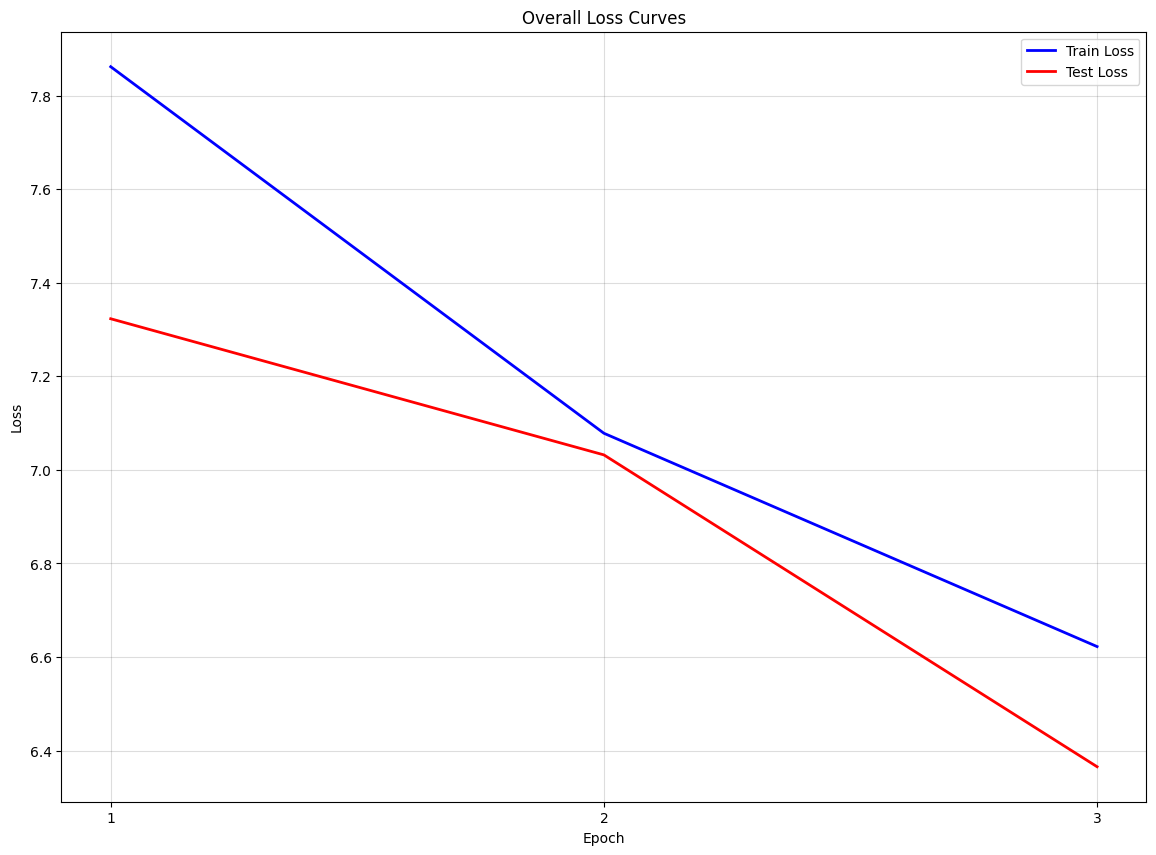

In [48]:

# plot the overall loss curves

import matplotlib.pyplot as plt 

epochs = range(1, len(history['train_loss']) + 1)

fig, ax = plt.subplots(figsize=(14, 10))
ax.plot(epochs, history['train_loss'],color='blue',linewidth=2, label='Train Loss')
ax.plot(epochs, history['test_loss'], color='red', linewidth=2, label='Test Loss')
ax.set_title('Overall Loss Curves')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_xticks(epochs)
ax.legend()
ax.grid(True, alpha=0.2, color='#555')
plt.show()



In [52]:
from hri_gnn.config.const import ENTITY_ATTRIBUTES

for letter, number, attribute in zip(['a','b','c','d'],[1,2,3,4], ENTITY_ATTRIBUTES.keys()):
    print(f"letter: {letter}, number: {number}, attribute: {attribute}")

letter: a, number: 1, attribute: type
letter: b, number: 2, attribute: size
letter: c, number: 3, attribute: color
letter: d, number: 4, attribute: angle


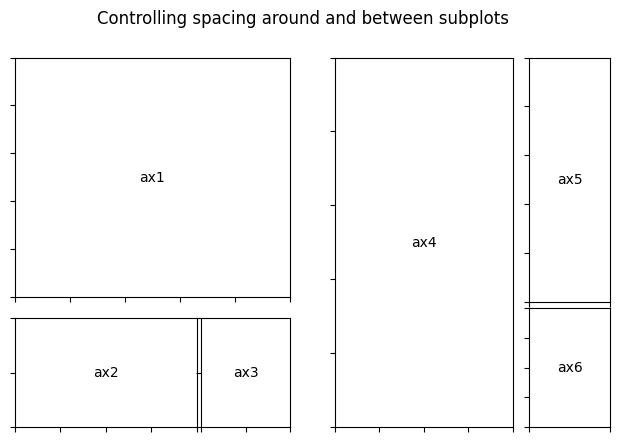

In [60]:
from matplotlib.gridspec import GridSpec
def annotate_axes(fig):
    for i, ax in enumerate(fig.axes):
        ax.text(0.5, 0.5, "ax%d" % (i+1), va="center", ha="center")
        ax.tick_params(labelbottom=False, labelleft=False)

fig = plt.figure()
fig.suptitle("Controlling spacing around and between subplots")

gs1 = GridSpec(3, 3, left=0.05, right=0.48, wspace=0.05)
ax1 = fig.add_subplot(gs1[:-1, :])
ax2 = fig.add_subplot(gs1[-1, :-1])
ax3 = fig.add_subplot(gs1[-1, -1])

gs2 = GridSpec(3, 3, left=0.55, right=0.98, hspace=0.05)
ax4 = fig.add_subplot(gs2[:, :-1])
ax5 = fig.add_subplot(gs2[:-1, -1])
ax6 = fig.add_subplot(gs2[-1, -1])

annotate_axes(fig)

plt.show()

In [68]:
positions = [
    (row, col)
    for row in range(2)
    for col in range(2)
]

tiles = [
    (f't{i+1}', position)
    for i, position in enumerate(positions)
]
tiles[0][1][0]

0

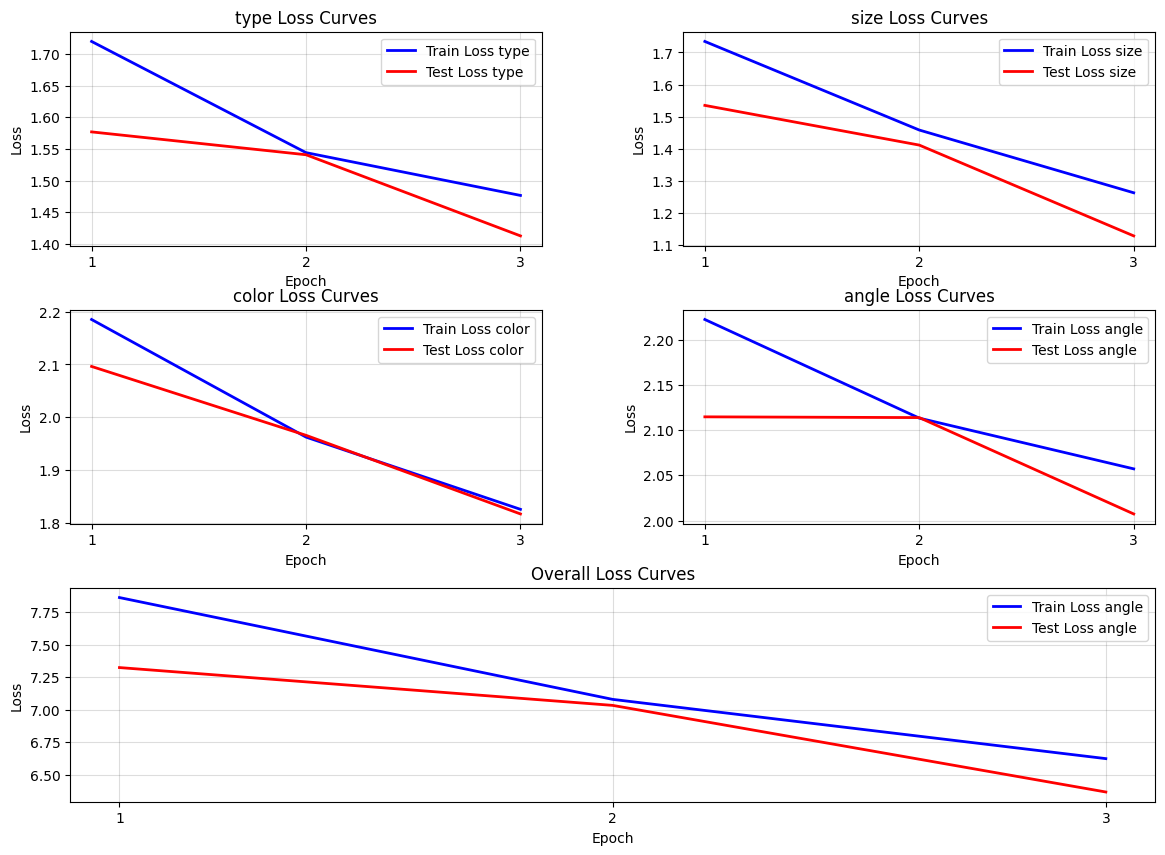

In [83]:
from hri_gnn.config.const import ENTITY_ATTRIBUTES

# plot the loss attributes curves 
rows, cols = 3,2
top_positions= [(row,col) for row in range(rows-1) for col in range(cols)]

gs = GridSpec(rows, cols, hspace=0.3,wspace=0.3)
fig = plt.figure(figsize=(14, 10))

for (row, col), attribute in zip(top_positions, ENTITY_ATTRIBUTES.keys()):
    ax = fig.add_subplot(gs[row,col])
    ax.plot(epochs, history[f'train_loss_{attribute}'],color='blue',linewidth=2, label=f'Train Loss {attribute}')
    ax.plot(epochs, history[f'test_loss_{attribute}'], color='red', linewidth=2, label=f'Test Loss {attribute}')
    ax.set_title(f'{attribute} Loss Curves')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.set_xticks(epochs)
    ax.legend()
    ax.grid(True, alpha=0.2, color='#555')

ax_overall = fig.add_subplot(gs[2,:])

ax_overall.plot(epochs, history[f'train_loss'],color='blue',linewidth=2, label=f'Train Loss {attribute}')
ax_overall.plot(epochs, history[f'test_loss'], color='red', linewidth=2, label=f'Test Loss {attribute}')
ax_overall.set_title(f'Overall Loss Curves')
ax_overall.set_xlabel('Epoch')
ax_overall.set_ylabel('Loss')
ax_overall.set_xticks(epochs)
ax_overall.legend()
ax_overall.grid(True, alpha=0.2, color='#555')

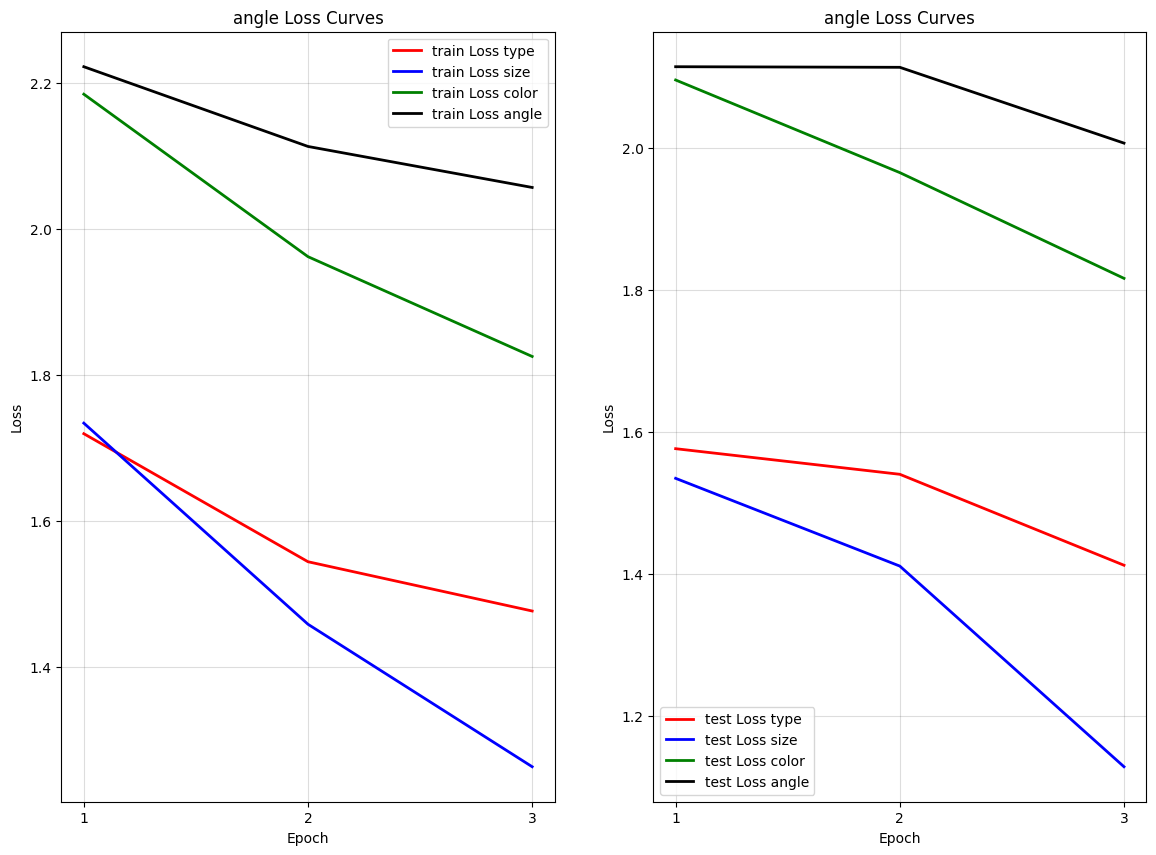

In [59]:
# plot all attributes train and loss curves
split=['train', 'test']
colors = ['red', 'blue', 'green', 'black']

fig, axes = plt.subplots(nrows=1, ncols=2,figsize=(14,10))
for ax, split in zip(axes.flat, split):
    for attribute, color in zip(ENTITY_ATTRIBUTES.keys(),colors):
        ax.plot(epochs, history[f'{split}_loss_{attribute}'],color=color,linewidth=2, label=f'{split} Loss {attribute}')
        ax.set_title(f'{attribute} Loss Curves')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        ax.set_xticks(epochs)
        ax.legend()
        ax.grid(True, alpha=0.2, color='#555')

## 2. Reasoning System (Graph Builder, GNN & HRI) 